# Fitting seeds, payload bytes and relative errors

The appendix on dispersion and fitting seeds, the storage in bytes and the relative errors (Tables 7, 8, 9 and 26).

Every method with a random part was fitted with several seeds on all 39 snapshots: GyroSplat and the neural field with the physics stage with seeds 0-4, the field-only neural field and splats with seeds 0-2 (`results/experiments/seeds.jsonl`). A table entry is the mean over seeds of the snapshot median; the dispersion is the snapshot quartiles of each seed, averaged over seeds; the seed variation is the standard deviation of the snapshot median over seeds.

In [1]:
import pathlib
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

REPO = pathlib.Path.cwd()
while not (REPO / "neugk").exists():  # the repository root
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
RESULTS = REPO / "neugk/gyrosplat/results"
CONFIGS = REPO / "configs/gyrosplat"

from neugk.gyrosplat.eval.paper import experiments as X
from neugk.gyrosplat.eval.paper import load_experiments, load_rows

rows = load_rows(RESULTS / "rows/gkw_rows.jsonl")
exp = load_experiments(RESULTS / "experiments")
FIGURES = RESULTS / "figures"
FIGURES.mkdir(exist_ok=True)

from neugk.gyrosplat.eval.paper.figures import paired_figure

## Payload bytes (Table 9)

The compression ratio is the raw snapshot (89,128,960 bytes) over the encoded payload. Sparse codes include the position of every kept coefficient; ZFP and SZ3 use their stream sizes, so their rates are approximate. The shared AE, VAE and VQ-VAE models and file containers are not part of the payload; they are listed below the table.

In [2]:
display(Markdown(X.bytes_table(exp)))
storage = exp["storage"]
for model, n in storage["shared_decoder_parameters"].items():
    print(f"shared {model} model: {n / 1e6:.1f} million parameters, {4 * n / 1e6:.1f} MB in fp32")
for tier, b in storage["archived_gyrosplat_file_bytes"].items():
    print(f"stored GyroSplat file, {tier}x budget: median {b:,} bytes, {storage['raw_snapshot_bytes'] / b:.1f}x")

| method | bytes, 302× | CR | bytes, 142× | CR |
|---|---|---|---|---|
| Wavelet bior4.4 | 294,928 | 302.2 | 626,688 | 142.2 |
| Wavelet Haar | 294,928 | 302.2 | 626,688 | 142.2 |
| PCA | 294,440 | 302.7 | 621,656 | 143.4 |
| ZFP | 292,400 | 304.8 | 615,200 | 144.9 |
| SZ3 | 296,336 | 300.8 | 624,196 | 142.8 |
| Fourier top-K | 294,924 | 302.2 | 626,688 | 142.2 |
| AE | 294,912 | 302.2 | — | — |
| VAE | 294,912 | 302.2 | — | — |
| VQ-VAE | 294,912 | 302.2 | — | — |
| NF, field only | 295,324 | 301.8 | 627,736 | 142.0 |
| Splats, field only | 294,928 | 302.2 | 626,640 | 142.2 |
| NF + physics | 295,324 | 301.8 | 627,736 | 142.0 |
| GyroSplat | 294,928 | 302.2 | 626,692 | 142.2 |
| Fourier + refinement | 294,924 | 302.2 | 626,688 | 142.2 |
| Haar + refinement | 294,928 | 302.2 | 626,688 | 142.2 |

shared autoencoder model: 217.6 million parameters, 870.5 MB in fp32
shared vae model: 217.9 million parameters, 871.6 MB in fp32
shared vqvae model: 230.0 million parameters, 920.1 MB in fp32
stored GyroSplat file, 142x budget: median 631,948 bytes, 141.0x
stored GyroSplat file, 302x budget: median 300,172 bytes, 296.9x


## Snapshot dispersion and seed variation (Table 7)

How one entry is formed, for GyroSplat's potential PSNR at 302×: the median over the 39 snapshots for each seed, then their mean and standard deviation.

In [3]:
import statistics

per_seed = X.samples(exp, rows, 302, "gyrosplat")
medians = {seed: statistics.median(r["psnr_phi"] for r in snaps.values()) for seed, snaps in per_seed.items()}
print({seed: round(v, 3) for seed, v in medians.items()})
print(f"mean {statistics.mean(medians.values()):.2f} dB, seed std {statistics.stdev(medians.values()):.2f} dB")

{0: 27.732, 1: 27.634, 2: 27.734, 3: 27.667, 4: 27.684}
mean 27.69 dB, seed std 0.04 dB


In [4]:
display(Markdown(X.seed_dispersion_table(exp, rows)))

| method | PSNR_f | PSNR_φ | flux relL1 |
|---|---|---|---|
| *Snapshot dispersion, CR ≈ 302×* | | | |
| Wavelet bior4.4 | 34.40 [33.84, 35.08] | -12.87 [-20.67, -3.89] | 1.143 [1.109, 1.164] |
| Wavelet Haar | 34.40 [33.87, 34.83] | -8.32 [-15.99, 1.39] | 1.009 [1.008, 1.012] |
| PCA | 35.08 [34.50, 36.06] | -2.54 [-8.68, 4.97] | 0.455 [0.347, 0.646] |
| ZFP | 32.72 [32.16, 33.13] | -5.61 [-12.59, 3.08] | 0.979 [0.930, 0.991] |
| SZ3 | 33.45 [32.54, 34.32] | -15.87 [-24.21, -9.32] | 1.287 [1.059, 1.442] |
| Fourier top-K | 35.25 [34.69, 35.99] | 21.36 [18.16, 25.11] | 0.289 [0.231, 0.325] |
| AE | 35.49 [34.86, 36.26] | 15.42 [11.77, 18.39] | 0.131 [0.099, 0.180] |
| VAE | 34.35 [33.58, 35.38] | 9.33 [6.81, 13.15] | 0.193 [0.146, 0.269] |
| VQ-VAE | 34.16 [33.42, 34.82] | 12.91 [9.50, 14.52] | 0.218 [0.182, 0.243] |
| NF, field only | 37.37 [36.75, 37.96] | 14.36 [11.24, 18.66] | 0.172 [0.132, 0.197] |
| Splats, field only | 39.32 [38.63, 40.10] | 7.38 [1.24, 12.85] | 0.271 [0.216, 0.325] |
| NF + physics | 37.29 [36.66, 37.86] | 26.63 [25.13, 29.59] | 0.142 [0.120, 0.162] |
| GyroSplat | 37.63 [37.07, 38.34] | 27.69 [26.81, 30.29] | 5.2×10⁻⁷ [5.8×10⁻⁸, 3.8×10⁻⁶] |
| Fourier + refinement | 35.23 [34.69, 35.99] | 23.19 [21.61, 26.39] | 0.024 [0.019, 0.033] |
| Haar + refinement | 12.90 [10.86, 13.65] | -15.08 [-20.83, -6.35] | 1.8×10⁻⁷ [1.5×10⁻⁷, 2.8×10⁻⁷] |
| *Snapshot dispersion, CR ≈ 142×* | | | |
| Wavelet bior4.4 | 36.57 [35.99, 37.19] | -12.25 [-19.35, -3.70] | 1.230 [1.159, 1.257] |
| Wavelet Haar | 36.26 [35.69, 36.75] | -7.83 [-15.10, 0.82] | 1.015 [1.010, 1.018] |
| PCA | 37.88 [37.33, 38.75] | 1.69 [-1.05, 7.87] | 0.351 [0.288, 0.428] |
| ZFP | 35.29 [34.80, 36.17] | -3.39 [-6.40, 4.69] | 0.799 [0.753, 0.892] |
| SZ3 | 38.42 [37.72, 39.38] | -12.23 [-21.36, -6.61] | 0.537 [0.439, 0.586] |
| Fourier top-K | 36.57 [35.92, 37.10] | 24.89 [22.84, 28.35] | 0.149 [0.132, 0.180] |
| NF, field only | 38.26 [37.54, 38.92] | 15.17 [12.49, 20.24] | 0.147 [0.112, 0.172] |
| Splats, field only | 41.44 [40.53, 42.04] | 9.31 [5.55, 13.66] | 0.166 [0.145, 0.191] |
| NF + physics | 38.16 [37.49, 38.80] | 27.56 [26.05, 30.05] | 0.105 [0.088, 0.123] |
| GyroSplat | 38.21 [37.61, 38.90] | 29.24 [28.52, 31.59] | 3.7×10⁻⁸ [1.7×10⁻⁸, 1.2×10⁻⁷] |
| Fourier + refinement | 36.57 [35.90, 37.07] | 25.98 [24.71, 29.06] | 0.008 [0.004, 0.009] |
| Haar + refinement | 22.82 [20.49, 24.66] | -11.42 [-17.72, -4.10] | 8.5×10⁻⁸ [5.9×10⁻⁸, 1.2×10⁻⁷] |
| *Fitting-seed variation: mean ± standard deviation of snapshot medians* | | | |
| GyroSplat, 302× (5 seeds) | 37.63 ± 0.02 | 27.69 ± 0.04 | 5.2×10⁻⁷ ± 2.0×10⁻⁷ |
| NF + physics, 302× (5 seeds) | 37.29 ± 0.10 | 26.63 ± 0.20 | 0.142 ± 0.002 |
| NF, field only, 302× (3 seeds) | 37.37 ± 0.07 | 14.36 ± 0.28 | 0.172 ± 0.004 |
| Splats, field only, 302× (3 seeds) | 39.32 ± 0.01 | 7.38 ± 0.60 | 0.271 ± 0.004 |
| GyroSplat, 142× (5 seeds) | 38.21 ± 0.03 | 29.24 ± 0.06 | 3.7×10⁻⁸ ± 5.1×10⁻⁹ |
| NF + physics, 142× (5 seeds) | 38.16 ± 0.14 | 27.56 ± 0.25 | 0.105 ± 0.003 |
| NF, field only, 142× (3 seeds) | 38.26 ± 0.21 | 15.17 ± 0.45 | 0.147 ± 0.007 |
| Splats, field only, 142× (3 seeds) | 41.44 ± 0.01 | 9.31 ± 0.94 | 0.166 ± 0.004 |

## Paired comparison with the neural field + physics

Per snapshot, the potential PSNR of GyroSplat minus that of the neural field with the physics stage, both averaged over their five seeds. The 39 snapshots come from 27 trajectories, so the differences are averaged per trajectory first; the median of the trajectory differences gets a 95% bootstrap interval over trajectories (10,000 resamples).

302x: median gain 1.16 dB (95% interval 0.75-1.53 dB) over 27 trajectories; positive on 35/39 snapshots
142x: median gain 2.13 dB (95% interval 1.63-2.85 dB) over 27 trajectories; positive on 38/39 snapshots


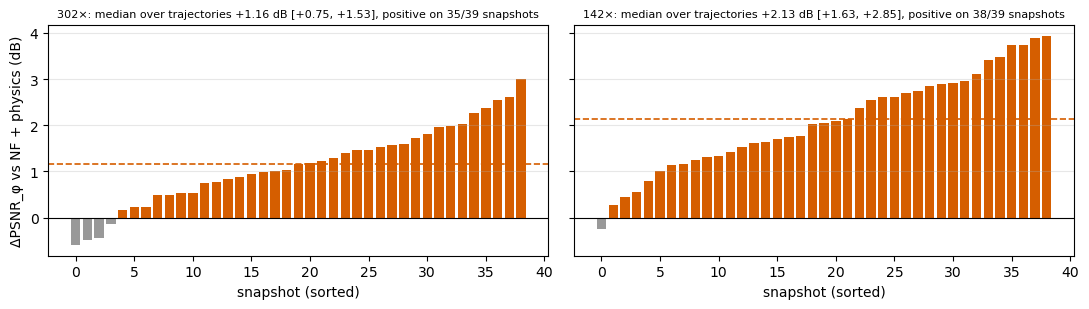

In [5]:
for tier in (302, 142):
    g = X.paired_gain(exp, tier)
    lo, hi = g["interval"]
    print(f"{tier}x: median gain {g['median']:.2f} dB (95% interval {lo:.2f}-{hi:.2f} dB) over {g['trajectories']} "
          f"trajectories; positive on {g['positive_snapshots']}/{g['snapshots']} snapshots")
fig = paired_figure(exp)
fig.savefig(FIGURES / "paired_potential_psnr.pdf", bbox_inches="tight")
plt.show()

## Turbulence regimes (Table 8)

Medians within the 12 streamer, 12 mixed and 15 strong-zonal snapshots at 302×, averaged over the fitting seeds.

In [6]:
display(Markdown(X.regime_table(exp, rows)))

| method | Streamer: PSNR_f | Streamer: PSNR_φ | Streamer: flux | Mixed: PSNR_f | Mixed: PSNR_φ | Mixed: flux | Strong zonal: PSNR_f | Strong zonal: PSNR_φ | Strong zonal: flux |
|---|---|---|---|---|---|---|---|---|---|
| Wavelet bior4.4 | 34.98 | -3.89 | 1.150 | 34.67 | -14.25 | 1.122 | 34.01 | -17.17 | 1.145 |
| Wavelet Haar | 34.67 | 1.39 | 1.013 | 34.61 | -9.69 | 1.009 | 33.99 | -12.02 | 1.009 |
| PCA | 34.71 | 6.16 | 0.535 | 35.45 | -5.83 | 0.585 | 35.08 | -4.39 | 0.349 |
| ZFP | 32.40 | 2.99 | 0.951 | 32.81 | -6.01 | 0.982 | 32.80 | -11.06 | 0.976 |
| SZ3 | 34.27 | -11.76 | 1.055 | 33.77 | -16.57 | 1.333 | 32.61 | -16.33 | 1.323 |
| Fourier top-K | 34.84 | 19.82 | 0.328 | 35.66 | 20.39 | 0.280 | 35.56 | 25.52 | 0.234 |
| AE | 34.15 | 17.09 | 0.192 | 35.91 | 12.37 | 0.129 | 36.06 | 16.01 | 0.100 |
| VAE | 32.45 | 12.61 | 0.285 | 34.71 | 8.56 | 0.197 | 34.97 | 8.70 | 0.148 |
| VQ-VAE | 33.30 | 13.51 | 0.248 | 34.41 | 12.08 | 0.222 | 34.48 | 12.69 | 0.179 |
| NF, field only | 37.28 | 17.15 | 0.194 | 37.70 | 13.64 | 0.171 | 37.19 | 13.53 | 0.141 |
| Splats, field only | 39.60 | 10.30 | 0.336 | 39.74 | 7.19 | 0.269 | 38.83 | 5.55 | 0.225 |
| NF + physics | 37.07 | 24.75 | 0.122 | 37.62 | 26.33 | 0.147 | 37.14 | 30.14 | 0.145 |
| GyroSplat | 37.21 | 26.99 | 1.2×10⁻⁶ | 38.10 | 27.04 | 2.8×10⁻⁷ | 37.63 | 30.93 | 6.3×10⁻⁷ |
| Fourier + refinement | 34.83 | 21.54 | 0.020 | 35.66 | 22.56 | 0.023 | 35.55 | 27.27 | 0.028 |
| Haar + refinement | 10.90 | -5.10 | 1.9×10⁻⁷ | 13.47 | -16.16 | 1.8×10⁻⁷ | 12.90 | -19.49 | 2.1×10⁻⁷ |

## Relative errors (Table 26)

PSNR divides by the peak of the reference. The relative L2 error ‖û − u‖₂ / ‖u‖₂ shows the error against the norm of the signal instead; same fits and seed averaging as Table 1.

In [7]:
display(Markdown(X.relative_error_table(exp, rows)))

| method | f, 302× | φ, 302× | f, 142× | φ, 142× |
|---|---|---|---|---|
| GyroSplat | 36% | 18% | 34% | 15% |
| NF + physics | 38% | 21% | 34% | 19% |
| NF | 38% | 77% | 34% | 70% |
| Splats, field only | 30% | 182% | 24% | 139% |
| Fourier + refinement | 51% | 31% | 43% | 22% |
| Haar + refinement | 661% | 2223% | 201% | 1371% |
| Fourier top-K | 51% | 39% | 43% | 25% |
| Wavelet top-K (bior4.4) | 54% | 1844% | 41% | 1753% |
| Wavelet top-K (Haar) | 54% | 1012% | 43% | 995% |
| Autoencoder | 47% | 67% | — | — |
| VAE | 54% | 125% | — | — |
| VQ-VAE | 58% | 96% | — | — |
| PCA | 50% | 565% | 37% | 306% |
| ZFP | 67% | 769% | 47% | 566% |
| SZ3 | 61% | 2240% | 34% | 1438% |